This notebooks is for detecting outliers, i.e. targets that were specific in a cell line or isoforms that lead to a different phenotype.

In [1]:
import yaml
import warnings
import sys

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
import PyComplexHeatmap as pch
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
# from utils import ...

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']

In [2]:
# Get counts
counts = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

# Cell line specificity

Targets that are differential hits between cell lines.

In [3]:
tab = pd.read_csv('../results/merged/gene_results_perline.csv', index_col=0, header=[0,1])

In [4]:
mageck_std = tab.loc[:, (slice(None), 'MAGeCK_score')].std(axis=1)
bagel2_std = tab.loc[:, (slice(None), 'Bagel2_Bayesfactor')].std(axis=1)
gscreend_std = tab.loc[:, (slice(None), 'Gscreend_FDR')].std(axis=1)
stab = pd.concat([mageck_std, bagel2_std, gscreend_std], axis=1, keys=['MAGeCK', 'Bagel2', 'Gscreend'])

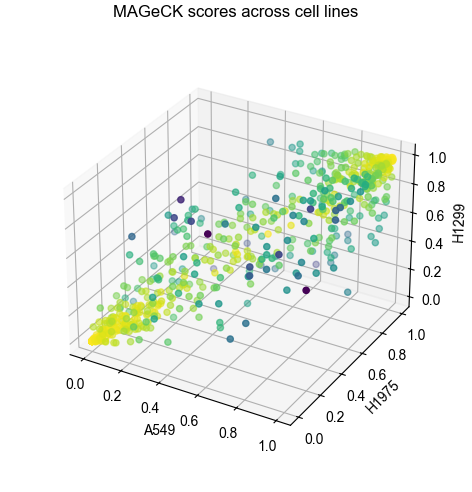

In [5]:
# make this an interactive 3d scatterplot instead
# sns.scatterplot(data=tab, x=('A549', 'MAGeCK_score'), y=('H1975', 'MAGeCK_score'), hue=('H1299', 'MAGeCK_score'))
fig, ax = pl.subplots(subplot_kw={'projection': '3d'}, figsize=(8,6))

# calculate distance from diagonal
dist = np.sqrt((tab.loc[:, ('A549', 'MAGeCK_score')] - tab.loc[:, ('H1975', 'MAGeCK_score')])**2 + (tab.loc[:, ('H1975', 'MAGeCK_score')] - tab.loc[:, ('H1299', 'MAGeCK_score')])**2)

ax.scatter(tab.loc[:, ('A549', 'MAGeCK_score')], tab.loc[:, ('H1975', 'MAGeCK_score')], tab.loc[:, ('H1299', 'MAGeCK_score')], c=dist, cmap='viridis_r', s=20)
ax.set_xlabel('A549')
ax.set_ylabel('H1975')
ax.set_zlabel('H1299')
ax.set_title('MAGeCK scores across cell lines')
ax.set_box_aspect(aspect=None, zoom=0.85)

pl.show()

<Axes: xlabel='None-None'>

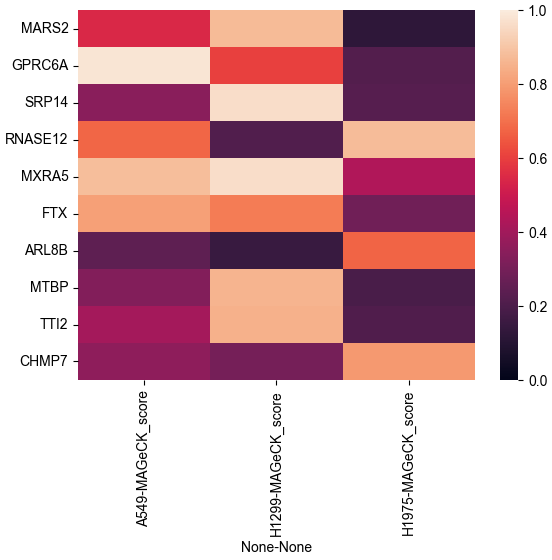

In [6]:
tops = pd.Series(dist).sort_values(ascending=False).head(10)
sns.heatmap(tab.loc[tops.index, (slice(None), 'MAGeCK_score')], vmin=0, vmax=1)

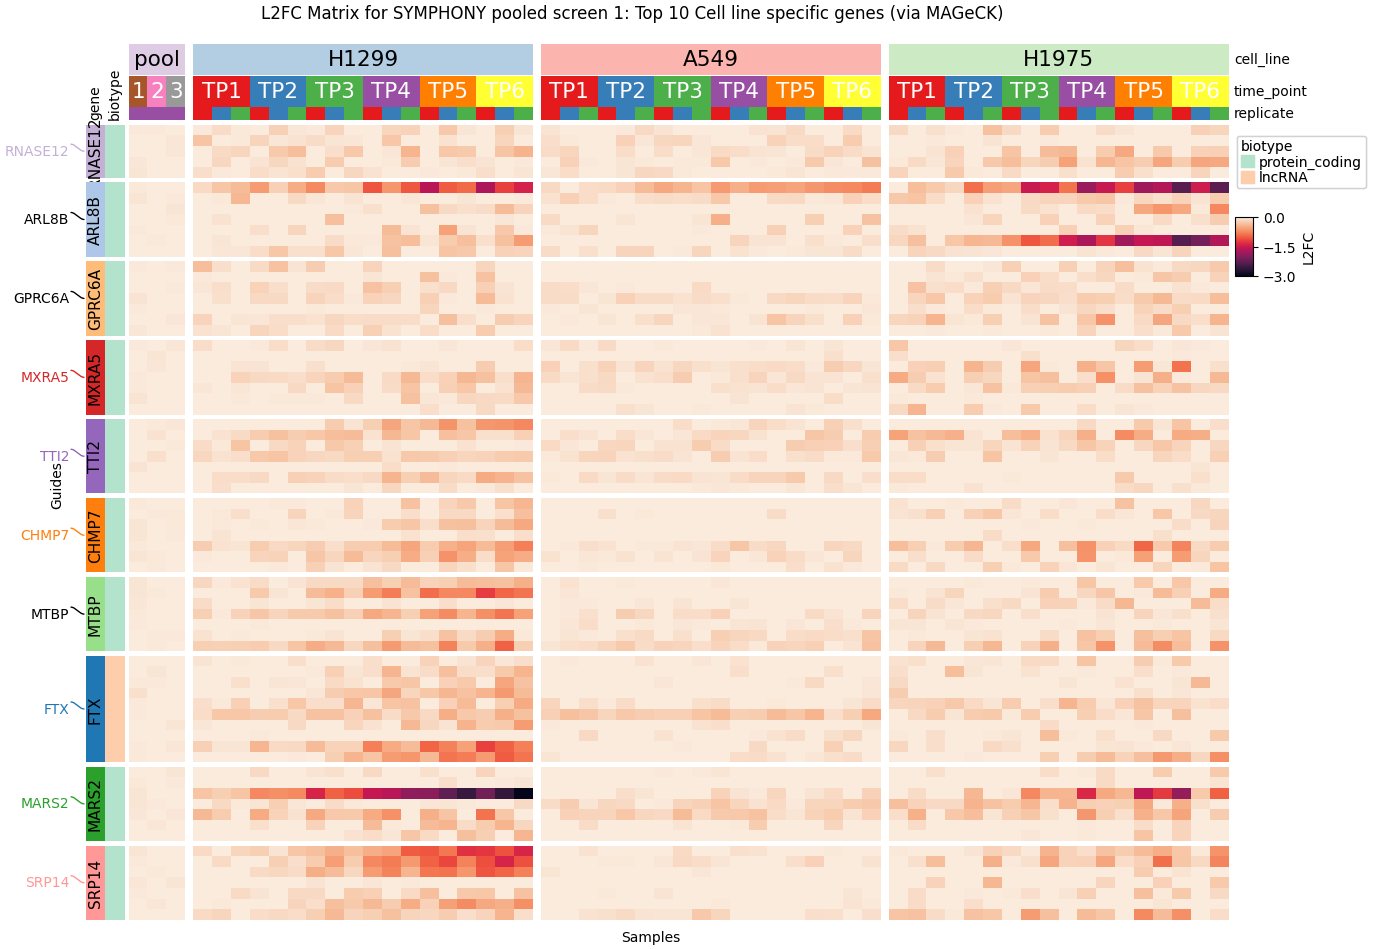

In [ ]:
# visualize in heatmap
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in df.index if 'control' in x.lower()]

# First I normalize for seq-depth by bringing all NT guides to the same count
target = df.loc[controls, sample_names_wo_pools].mean().mean()  # mean of NTs in control
ist = df.loc[controls, sample_names].mean()  # mean of NTs in all
norm_factor = target / ist  # make all NT mean counts equal to those in control
ndf = df.loc[:, sample_names] * norm_factor  # normalize

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T  # normalize to control (pools)
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

import PyComplexHeatmap as pch
df['mean_l2fc'] = l2fc.mean(axis=1)

df = df[df.Gene.isin(tops.index)]
l2fc = l2fc.loc[df.index]

biotype = df.sort_values(['transcript_biotype', 'mean_l2fc']).transcript_biotype
biotype = biotype[~biotype.isin(['protein_coding_CDS_not_defined', 'retained_intron'])]

cell_line_dict_ = {f'0{x}': y for x, y in cell_line_dict.items()}
cell_line = pd.Series({x: x.split('-')[1] for x in sample_names}).replace(cell_line_dict_)
replicate = pd.Series({x: x.split('-')[2] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in sample_names})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

# select and reorder
data = l2fc.loc[:, col_order]

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, cmap='Pastel1'),
    time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=7, cmap='Set1'),
    replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
    verbose=0, axis=1, plot_legend=False
)

left_ha = pch.HeatmapAnnotation(
    label=pch.anno_label(df.Gene, merge=True, cmap='tab20'),
    gene=pch.anno_simple(df.Gene, legend=False, height=5, add_text=True, cmap='tab20'),
    biotype=pch.anno_simple(biotype, legend=True, height=5, add_text=False, cmap='Pastel2'),
    verbose=0, axis=0, plot_legend=True
)

pl.figure(figsize=(15, 10))
cm = pch.ClusterMapPlotter(
    data=data, 
    left_annotation=left_ha, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    col_split=cell_line.loc[col_order],
    col_split_gap=2, row_split_gap=1,
    row_split=df.Gene,
    label='beta', row_dendrogram=False, col_dendrogram=False,
    legend_gap=7, rasterized=True, cmap='rocket', vmin=-3, vmax=0,
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='Guides', legend_hpad=0,
    verbose=0
)
pl.suptitle('L2FC Matrix for SYMPHONY pooled screen 1: Top 10 Cell line specific genes (via MAGeCK)', y=0.92)
# pl.savefig('../results/figures/count_matrix_l2fc_heatmap_simple.png', dpi=300)
# pl.savefig('../results/figures/count_matrix_l2fc_heatmap_simple.pdf', dpi=300)
pl.show()

In [ ]:
tab = pd.read_csv('../results/merged/transcript_results_perline.csv', index_col=0, header=[0,1])

In [ ]:
# mageck_std = tab.loc[:, (slice(None), 'MAGeCK_score')].std(axis=1)
# bagel2_std = tab.loc[:, (slice(None), 'Bagel2_Bayesfactor')].std(axis=1)
# gscreend_std = tab.loc[:, (slice(None), 'Gscreend_FDR')].std(axis=1)
# stab = pd.concat([mageck_std, bagel2_std, gscreend_std], axis=1, keys=['MAGeCK', 'Bagel2', 'Gscreend'])

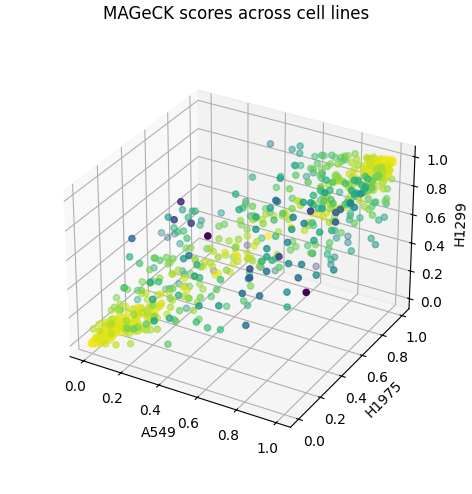

In [ ]:
# make this an interactive 3d scatterplot instead
# sns.scatterplot(data=tab, x=('A549', 'MAGeCK_score'), y=('H1975', 'MAGeCK_score'), hue=('H1299', 'MAGeCK_score'))
fig, ax = pl.subplots(subplot_kw={'projection': '3d'}, figsize=(8,6))

# calculate distance from diagonal
dist = np.sqrt((tab.loc[:, ('A549', 'MAGeCK_score')] - tab.loc[:, ('H1975', 'MAGeCK_score')])**2 + (tab.loc[:, ('H1975', 'MAGeCK_score')] - tab.loc[:, ('H1299', 'MAGeCK_score')])**2)

ax.scatter(tab.loc[:, ('A549', 'MAGeCK_score')], tab.loc[:, ('H1975', 'MAGeCK_score')], tab.loc[:, ('H1299', 'MAGeCK_score')], c=dist, cmap='viridis_r', s=20)
ax.set_xlabel('A549')
ax.set_ylabel('H1975')
ax.set_zlabel('H1299')
ax.set_title('MAGeCK scores across cell lines')
ax.set_box_aspect(aspect=None, zoom=0.85)

pl.show()

<Axes: xlabel='None-None', ylabel='id'>

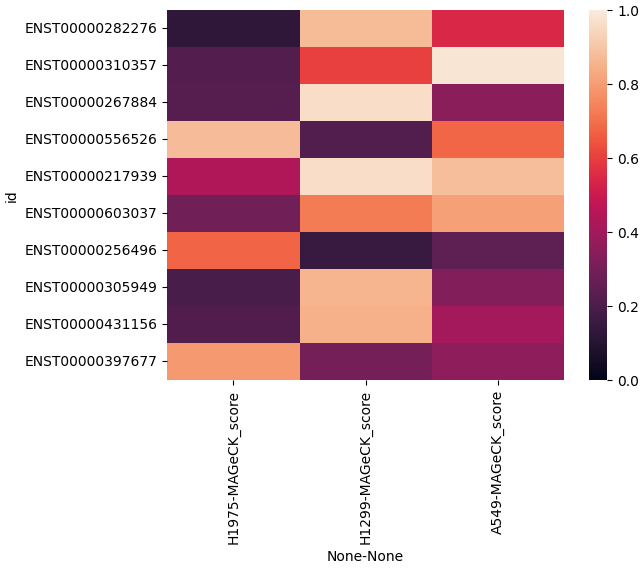

In [ ]:
tops = pd.Series(dist).sort_values(ascending=False).head(10)
sns.heatmap(tab.loc[tops.index, (slice(None), 'MAGeCK_score')], vmin=0, vmax=1)

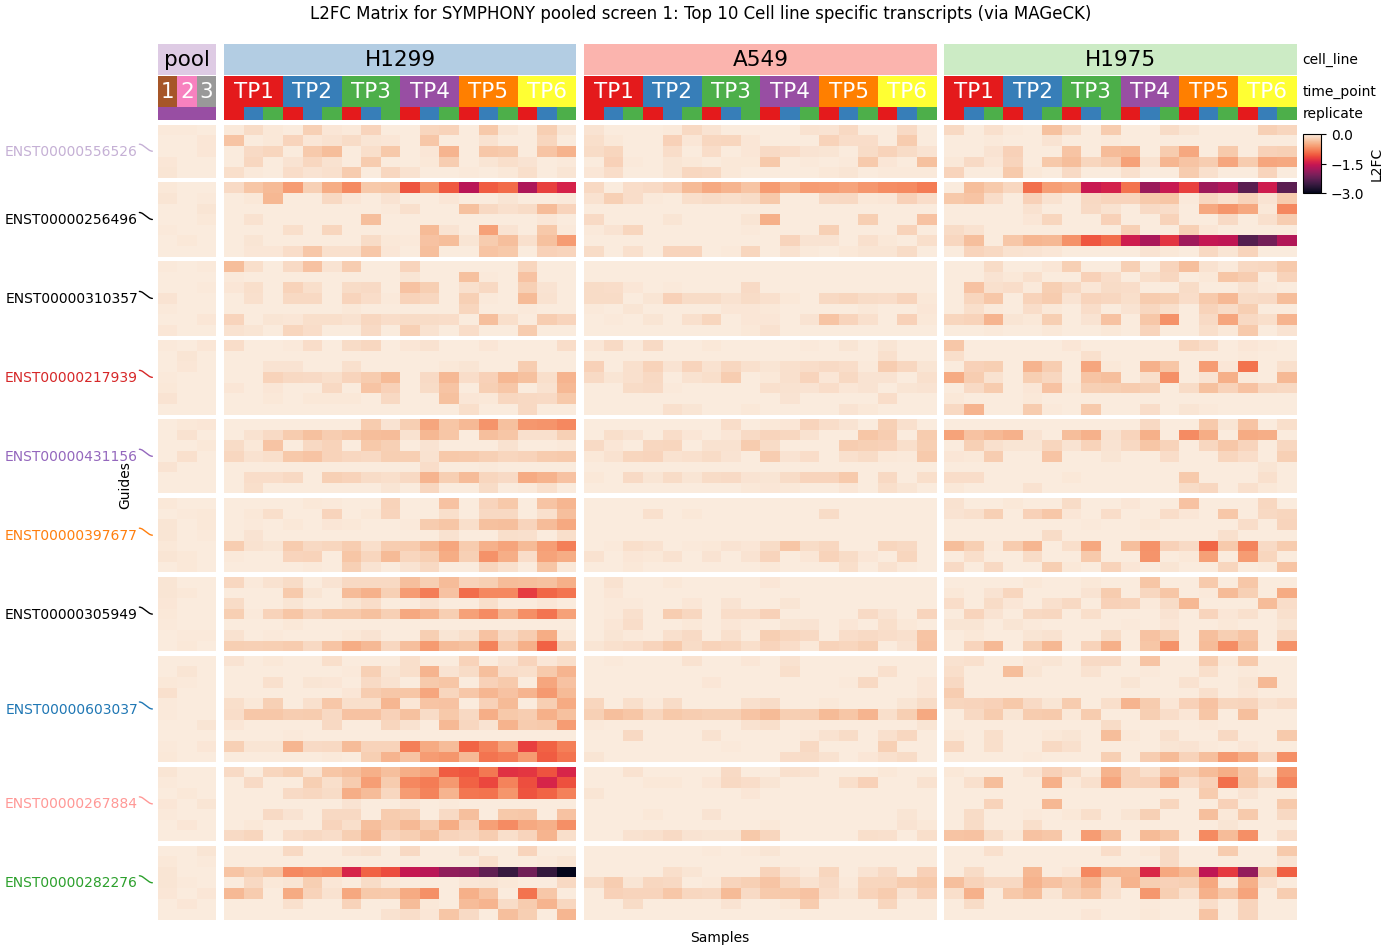

In [ ]:
# visualize in heatmap
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in df.index if 'control' in x.lower()]

# First I normalize for seq-depth by bringing all NT guides to the same count
target = df.loc[controls, sample_names_wo_pools].mean().mean()  # mean of NTs in control
ist = df.loc[controls, sample_names].mean()  # mean of NTs in all
norm_factor = target / ist  # make all NT mean counts equal to those in control
ndf = df.loc[:, sample_names] * norm_factor  # normalize

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T  # normalize to control (pools)
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

import PyComplexHeatmap as pch
df['mean_l2fc'] = l2fc.mean(axis=1)

df = df[df.Transcript_ID.isin(tops.index)]
l2fc = l2fc.loc[df.index]

biotype = df.sort_values(['transcript_biotype', 'mean_l2fc']).transcript_biotype
biotype = biotype[~biotype.isin(['protein_coding_CDS_not_defined', 'retained_intron'])]

cell_line_dict_ = {f'0{x}': y for x, y in cell_line_dict.items()}
cell_line = pd.Series({x: x.split('-')[1] for x in sample_names}).replace(cell_line_dict_)
replicate = pd.Series({x: x.split('-')[2] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in sample_names})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

# select and reorder
data = l2fc.loc[:, col_order]

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, cmap='Pastel1'),
    time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=7, cmap='Set1'),
    replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
    verbose=0, axis=1, plot_legend=False
)

left_ha = pch.HeatmapAnnotation(
    label=pch.anno_label(df.Transcript_ID, merge=True, cmap='tab20'),
    verbose=0, axis=0, plot_legend=True
)

pl.figure(figsize=(15, 10))
cm = pch.ClusterMapPlotter(
    data=data, 
    left_annotation=left_ha, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    col_split=cell_line.loc[col_order],
    col_split_gap=2, row_split_gap=1,
    row_split=df.Transcript_ID,
    label='beta', row_dendrogram=False, col_dendrogram=False,
    legend_gap=7, rasterized=True, cmap='rocket', vmin=-3, vmax=0,
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='Guides', legend_hpad=0,
    verbose=0
)
pl.suptitle('L2FC Matrix for SYMPHONY pooled screen 1: Top 10 Cell line specific transcripts (via MAGeCK)', y=0.92)
# pl.savefig('../results/figures/count_matrix_l2fc_heatmap_simple.png', dpi=300)
# pl.savefig('../results/figures/count_matrix_l2fc_heatmap_simple.pdf', dpi=300)
pl.show()

# Isoform specificity